# MOD550 — Assignment 3, Part II
## A 1-D convolutional network on raw bearing vibration

**Architecture chosen: Option B — CNN.**

---

### Group Information and Selected Architecture

| | |
|---|---|
| **Course** | MOD550 — Engineering Machine Learning with Real-World Data |
| **Assignment** | 3, Part II — Deep Learning |
| **Group members** | *(fill in: full names of all members)* |
| **This repository belongs to** | ... |
| **Architecture** | Option B — 1-D CNN |
| **Dataset** | the **same** CWRU windows as Part I, unchanged |
| **Split** | the **same** held-out-load split as Part I |

**Why a CNN and not an RNN/LSTM.** The input is a 2048-sample slice of an accelerometer
channel, a structured signal, which is what Option B names. What identifies a bearing
fault in that slice is a short, repeating impact transient, perhaps a hundred samples long,
that can occur anywhere in the window. A 1-D convolution is built for exactly that: a bank
of filters slid across the signal, so the same shape is detected wherever it falls, and
pooling then discards the position. An LSTM would instead have to carry state across 2048
time steps to recognise a pattern that is purely local and whose absolute position carries
no information: more parameters, a much slower sequential pass, and no benefit. We use an
LSTM when order over long spans matters, which here it does not.

> The *Supplement* after Task II.4 applies the methods of the MOD550 CNN lab to the same
> data. It is outside the word-limited reports and changes no number in Tasks II.1 to II.4.

**Contents**

1. [Task II.1 — Engineering problem and dataset](#task-ii1)
2. [Task II.2 — Data preparation and implementation](#task-ii2)
3. [Task II.3 — Training and evaluation](#task-ii3)
4. [Task II.4 — Model behaviour](#task-ii4)
5. [Supplement: the MOD550 CNN lab methods on the same data](#supplement)
6. [Individual Analysis](#individual)

In [1]:
import os
import sys
import time
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

sys.path.insert(0, "scripts")
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

SEED = 42
keras.utils.set_random_seed(SEED)

INK = "#44403c"
LOC_HUE = {"Normal": INK, "Ball": "#2a78d6", "Inner": "#eb6834", "Outer": "#1baf7a"}
LOC_RAMP = {"Ball": ["#6ba6e4", "#2a78d6", "#17457c"],
            "Inner": ["#ef8f62", "#eb6834", "#8f3a16"],
            "Outer": ["#52c49e", "#1baf7a", "#0d6348"]}
SIZES = ["007", "014", "021"]


def class_colour(name):
    if name == "Normal":
        return INK
    loc, size = name.split("_")
    return LOC_RAMP[loc][SIZES.index(size)]


mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b8b5ad", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e4de", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "figure.facecolor": "white",
})
print(f"tensorflow {tf.__version__} | keras {keras.__version__} | "
      f"devices: {[d.device_type for d in tf.config.list_physical_devices()]}")

I0000 00:00:1794079613.744068    1883 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794079614.940685    1883 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


tensorflow 2.21.0 | keras 3.15.1 | devices: ['CPU']


<a id="task-ii1"></a>
---
## Task II.1 — Engineering Problem and Dataset

### Dataset description and model justification (98 words)

Unchanged from Part I: CWRU drive-end accelerometer recordings of an SKF 6205 bearing at
12 kHz and four motor loads, cut into **3275 non-overlapping windows of 2048 samples** in
the same ten classes (healthy, plus ball, inner and outer faults at three diameters).
Part I gave an SVM 33 engineered features per window; Part II gives the network the
**raw waveform**. A 1-D CNN suits this because the diagnostic content is a short impact
transient repeating at a fault-dependent rate that may sit anywhere in the window:
convolution finds it wherever it falls, and pooling discards that position.

> Origin, citation and licence are unchanged from Task I.1; `scripts/cwru_data.py` loads it.

In [2]:
from cwru_data import CLASSES, FS, WINDOW, build_dataset, make_split

X, y, meta, recs = build_dataset()
tr, va, te = make_split(meta)

print(f"windows {X.shape[0]:,}   window length {WINDOW} samples "
      f"({WINDOW/FS*1000:.1f} ms at {FS} Hz)   classes {len(CLASSES)}")
print(pd.DataFrame({
    "train (0+1 hp)": np.bincount(y[tr], minlength=10),
    "val (2 hp)": np.bincount(y[va], minlength=10),
    "test (3 hp)": np.bincount(y[te], minlength=10)}, index=CLASSES).to_string())
print("\nrecordings shared between train and test:",
      len(set(meta["rec_id"][tr]) & set(meta["rec_id"][te])))

windows 3,275   window length 2048 samples (170.7 ms at 12000 Hz)   classes 10
           train (0+1 hp)  val (2 hp)  test (3 hp)
Normal                 88          59           59
Ball_007              118          59           59
Ball_014              118          59           59
Ball_021              118          59           59
Inner_007             118          59           60
Inner_014             118          59           59
Inner_021             118          59           59
Outer_007             354         177          177
Outer_014             118          59           59
Outer_021             354         177          177

recordings shared between train and test: 0


<a id="task-ii2"></a>
---
## Task II.2 — Data Preparation and Implementation

### II.2.1 — Inputs, targets and the split

**Splits.** Identical to Part I, and produced by the same `make_split` function: train on
motor loads 0 and 1 hp, validate on 2 hp, test on 3 hp. Because both notebooks call the
same function on the same windows, the CNN below is fitted on exactly the windows the SVM
was fitted on and scored on exactly the windows the SVM was scored on. That is what makes
the comparison in Task II.3 a comparison of *models* rather than of pipelines.

**No leakage.** Every recording belongs to exactly one load, so no recording is split
across train, validation and test; windows are non-overlapping, so no two windows share a
sample. The count above confirms zero shared recordings.

**Scaling.** One mean and one standard deviation, computed over the **training windows
only**, applied to all three sets. Deliberately *not* per-window normalisation: window-wise
scaling would divide out overall vibration amplitude, and amplitude is diagnostic here:
a healthy bearing runs at 0.06 g RMS and a 0.021" outer-race fault at 0.40 g. Throwing that
away would discard the single most informative measurement the sensor makes.

In [3]:
mu, sd = float(X[tr].mean()), float(X[tr].std())
Xtr = ((X[tr] - mu) / sd)[..., None].astype("float32")
Xva = ((X[va] - mu) / sd)[..., None].astype("float32")
Xte = ((X[te] - mu) / sd)[..., None].astype("float32")
ytr, yva, yte = y[tr], y[va], y[te]

print(f"scaler fitted on training windows only:  mean {mu:+.5f}   std {sd:.5f}")
print(f"X_train {Xtr.shape}   X_val {Xva.shape}   X_test {Xte.shape}")
print(f"after scaling -> train mean {Xtr.mean():+.4f} std {Xtr.std():.4f} | "
      f"test mean {Xte.mean():+.4f} std {Xte.std():.4f}")

# the 3.4:1 imbalance is handled the same way as in Part I
class_weight = {i: len(ytr) / (len(CLASSES) * (ytr == i).sum()) for i in range(len(CLASSES))}
print("\nclass weights:", {CLASSES[k]: round(v, 2) for k, v in class_weight.items()})

scaler fitted on training windows only:  mean +0.01122   std 0.38995
X_train (1622, 2048, 1)   X_val (826, 2048, 1)   X_test (827, 2048, 1)
after scaling -> train mean -0.0000 std 1.0000 | test mean -0.0171 std 0.9508

class weights: {'Normal': np.float64(1.84), 'Ball_007': np.float64(1.37), 'Ball_014': np.float64(1.37), 'Ball_021': np.float64(1.37), 'Inner_007': np.float64(1.37), 'Inner_014': np.float64(1.37), 'Inner_021': np.float64(1.37), 'Outer_007': np.float64(0.46), 'Outer_014': np.float64(1.37), 'Outer_021': np.float64(0.46)}


### II.2.2 — The architecture and what each part does

In [4]:
def build_cnn(filters1=16, filters2=32, kernel1=64, stride1=8, dense=64,
              dropout=0.3, seed=SEED):
    """Two convolutional layers, global pooling, one hidden dense layer."""
    keras.utils.set_random_seed(seed)
    return keras.Sequential([
        keras.Input(shape=(WINDOW, 1), name="raw_window"),
        # wide kernel: 64 samples = 5.3 ms, long enough to contain one impact transient
        layers.Conv1D(filters1, kernel1, strides=stride1, activation="relu",
                      padding="valid", name="conv_wide"),
        layers.BatchNormalization(name="bn_1"),
        layers.MaxPooling1D(2, name="pool_1"),
        # narrow kernel: combines neighbouring transients into a rate/pattern
        layers.Conv1D(filters2, 3, activation="relu", padding="same", name="conv_narrow"),
        layers.BatchNormalization(name="bn_2"),
        layers.MaxPooling1D(2, name="pool_2"),
        # aggregation over time -> the answer cannot depend on where in the window
        # the impacts happened to fall
        layers.GlobalAveragePooling1D(name="aggregate_over_time"),
        layers.Dense(dense, activation="relu", name="hidden"),
        layers.Dropout(dropout, seed=seed, name="dropout"),
        layers.Dense(len(CLASSES), activation="softmax", name="class_scores"),
    ], name="bearing_cnn_1d")


model = build_cnn()
model.summary()

n_train = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"\ninput shape          : ({WINDOW}, 1)  = {WINDOW/FS*1000:.1f} ms of acceleration")
print(f"conv_wide            : {model.get_layer('conv_wide').filters} filters, "
      f"kernel {model.get_layer('conv_wide').kernel_size[0]} "
      f"({model.get_layer('conv_wide').kernel_size[0]/FS*1000:.1f} ms), "
      f"stride {model.get_layer('conv_wide').strides[0]}")
print(f"conv_narrow          : {model.get_layer('conv_narrow').filters} filters, "
      f"kernel {model.get_layer('conv_narrow').kernel_size[0]}")
print(f"trainable parameters : {n_train:,}")
print(f"training windows     : {len(Xtr):,}   "
      f"-> {len(Xtr)/n_train:.2f} training examples per parameter")

Model: "bearing_cnn_1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_wide (Conv1D)              │ (None, 249, 16)        │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 249, 16)        │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling1D)           │ (None, 124, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_narrow (Conv1D)            │ (None, 124, 32)        │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 124, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling1D)           │ (None, 62, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aggregate_over_time             │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden (Dense)                  │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_scores (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,562 (21.73 KB)

 Trainable params: 5,466 (21.35 KB)

 Non-trainable params: 96 (384.00 B)


input shape          : (2048, 1)  = 170.7 ms of acceleration
conv_wide            : 16 filters, kernel 64 (5.3 ms), stride 8
conv_narrow          : 32 filters, kernel 3
trainable parameters : 5,466
training windows     : 1,622   -> 0.30 training examples per parameter


**The components, and why each is there.**

| Layer | Choice | Reason |
|---|---|---|
| `conv_wide` | 16 filters, kernel **64**, stride 8 | 64 samples is 5.3 ms at 12 kHz, long enough to span a whole impact transient, so one filter can learn the *shape* of an impact. A wide first kernel is standard practice for vibration input; a 3-sample kernel would only see noise. The stride of 8 reduces 2048 to 249 steps immediately, which keeps the model small. |
| `BatchNormalization` | after each conv | the input amplitude differs several-fold between classes and loads; normalising activations keeps gradients stable and training reproducible |
| `MaxPooling1D(2)` | after each block | halves the time axis and makes the response tolerant to small shifts in when an impact occurs |
| `conv_narrow` | 32 filters, kernel 3 | combines neighbouring impact detections into a pattern: how impacts are spaced, which is the fault-rate information |
| `GlobalAveragePooling1D` | instead of `Flatten` | the fault does not care *where* in the 0.17 s the impacts fell. `Flatten` would produce 1984 inputs to the dense layer and ~127k parameters for 1622 training windows; global pooling gives 32 and makes the model shift-invariant by construction. |
| `Dense(64)` + `Dropout(0.3)` | one hidden layer | enough to combine the 32 learned descriptors; dropout because the training set is small |
| `Dense(10, softmax)` | output | ten mutually exclusive classes |

The whole network holds **5,466 trainable parameters** for 1,622 training windows, about
0.30 windows per parameter. That is already thin, which is why the capacity study in
Task II.4 matters.

<a id="task-ii3"></a>
---
## Task II.3 — Training and Evaluation

**Optimizer:** Adam, learning rate 1e-3, the standard first choice, and it converged
without tuning.
**Loss:** sparse categorical cross-entropy: ten mutually exclusive classes with integer
labels, so the labels need no one-hot encoding.
**Batch size:** 64. **Maximum epochs: 120.**
**Stopping rule:** `EarlyStopping` on **validation loss**, patience **15** epochs,
`restore_best_weights=True`. Training therefore stops once the 2 hp validation loss has
failed to improve for 15 consecutive epochs, and the weights kept are those from the best
epoch, not the last. The test load plays no part in stopping.

In [5]:
MAX_EPOCHS, PATIENCE, BATCH = 120, 15, 64


def train_cnn(model, verbose=0, seed=SEED):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                       restore_best_weights=True, verbose=verbose)
    t0 = time.time()
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS,
                     batch_size=BATCH, class_weight=class_weight,
                     callbacks=[cb], verbose=verbose, shuffle=True)
    return hist, time.time() - t0


model = build_cnn(seed=SEED)
history, secs = train_cnn(model)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"stopped after {len(history.history['loss'])} epochs in {secs:.0f}s "
      f"(max {MAX_EPOCHS}); best validation loss at epoch {best_epoch}")
print(f"train accuracy {history.history['accuracy'][-1]:.4f} | "
      f"validation accuracy {history.history['val_accuracy'][-1]:.4f}")

stopped after 79 epochs in 35s (max 120); best validation loss at epoch 64
train accuracy 1.0000 | validation accuracy 1.0000


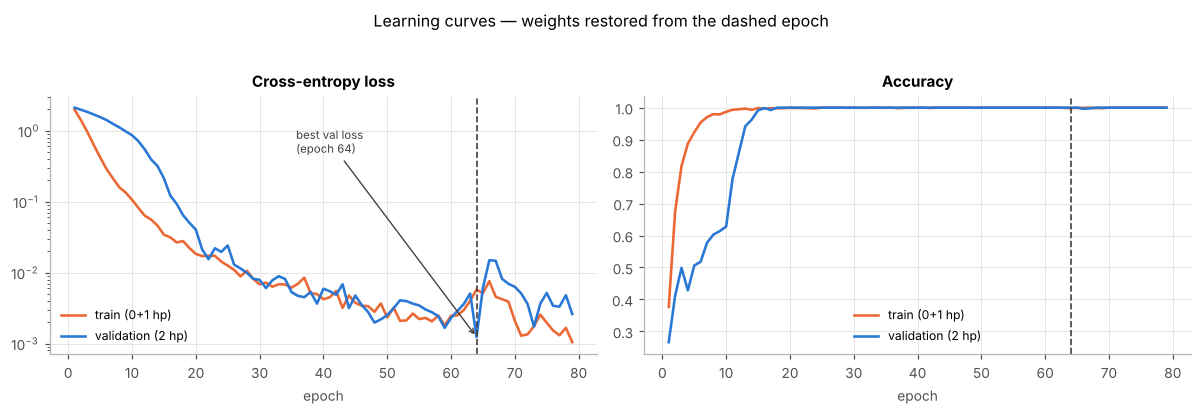

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ep = np.arange(1, len(history.history["loss"]) + 1)
for ax, (a, b, ttl) in zip(axes, [("loss", "val_loss", "Cross-entropy loss"),
                                  ("accuracy", "val_accuracy", "Accuracy")]):
    ax.plot(ep, history.history[a], color=LOC_HUE["Inner"], lw=1.7, label="train (0+1 hp)")
    ax.plot(ep, history.history[b], color=LOC_HUE["Ball"], lw=1.7, label="validation (2 hp)")
    ax.axvline(best_epoch, color=INK, ls="--", lw=1.1)
    ax.set_xlabel("epoch"); ax.set_title(ttl); ax.legend(fontsize=8)
axes[0].set_yscale("log")
axes[0].annotate(f"best val loss\n(epoch {best_epoch})", xy=(best_epoch,
                 history.history["val_loss"][best_epoch - 1]),
                 xytext=(0.45, 0.78), textcoords="axes fraction", fontsize=7.5, color=INK,
                 arrowprops=dict(arrowstyle="->", color=INK, lw=0.9))
plt.suptitle("Learning curves — weights restored from the dashed epoch", y=1.03, fontsize=10.5)
plt.tight_layout(); plt.savefig("figures/ii3_learning_curves.png"); plt.show()

Train and validation move together throughout and both reach 1.000 accuracy, so there is no
overfitting *to the validation load*. That is worth saying carefully, because it is exactly
what the SVMs did in Part I and it turned out to mean very little: the 2 hp load sits
between the two training loads and is simply easy. The curves cannot tell us how the model
behaves at 3 hp. Only the test load can.

In [7]:
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, f1_score, precision_recall_fscore_support)

proba = model.predict(Xte, verbose=0)
pred_cnn = proba.argmax(1)
acc = (pred_cnn == yte).mean()
pr, rc, f1, _ = precision_recall_fscore_support(yte, pred_cnn, average="macro", zero_division=0)
_, _, f1w, _ = precision_recall_fscore_support(yte, pred_cnn, average="weighted", zero_division=0)

print("HELD-OUT TEST — motor load 3 hp, 827 windows, scored once\n")
print(f"  accuracy          {acc:.4f}")
print(f"  precision (macro) {pr:.4f}")
print(f"  recall    (macro) {rc:.4f}")
print(f"  F1        (macro) {f1:.4f}      <- primary metric, as in Part I")
print(f"  F1     (weighted) {f1w:.4f}")
print()
print(classification_report(yte, pred_cnn, target_names=CLASSES, digits=3, zero_division=0))

HELD-OUT TEST — motor load 3 hp, 827 windows, scored once

  accuracy          0.8585
  precision (macro) 0.7939
  recall    (macro) 0.8017
  F1        (macro) 0.7345      <- primary metric, as in Part I
  F1     (weighted) 0.8106

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000        59
    Ball_007      0.527     1.000     0.690        59
    Ball_014      0.504     1.000     0.670        59
    Ball_021      1.000     0.017     0.033        59
   Inner_007      1.000     1.000     1.000        60
   Inner_014      0.000     0.000     0.000        59
   Inner_021      1.000     1.000     1.000        59
   Outer_007      1.000     1.000     1.000       177
   Outer_014      0.908     1.000     0.952        59
   Outer_021      1.000     1.000     1.000       177

    accuracy                          0.859       827
   macro avg      0.794     0.802     0.735       827
weighted avg      0.853     0.859     0.811       827



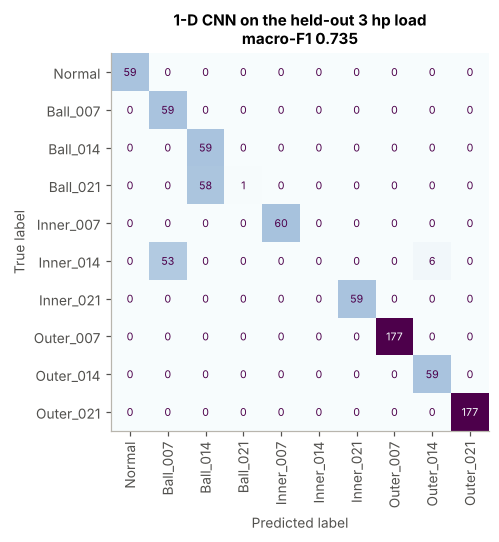

faults called healthy : 0 / 768
healthy called faulty : 0 / 59
fault LOCATION correct: 0.9287
full ten-class correct: 0.8585


In [8]:
fig, ax = plt.subplots(figsize=(5.6, 5))
ConfusionMatrixDisplay(confusion_matrix(yte, pred_cnn), display_labels=CLASSES).plot(
    ax=ax, cmap="BuPu", colorbar=False, values_format="d", xticks_rotation=90)
ax.set_title(f"1-D CNN on the held-out 3 hp load\nmacro-F1 {f1:.3f}", fontsize=10)
ax.grid(False)
for t in ax.texts:
    t.set_fontsize(7)
plt.tight_layout(); plt.savefig("figures/ii3_confusion.png"); plt.show()

miss = int(((yte != 0) & (pred_cnn == 0)).sum())
fa = int(((yte == 0) & (pred_cnn != 0)).sum())
loc_of = np.array([c.split("_")[0] for c in CLASSES])
print(f"faults called healthy : {miss} / {int((yte!=0).sum())}")
print(f"healthy called faulty : {fa} / {int((yte==0).sum())}")
print(f"fault LOCATION correct: {(loc_of[pred_cnn]==loc_of[yte]).mean():.4f}")
print(f"full ten-class correct: {acc:.4f}")

Two things stand out, and the second is a warning.

**The safety-critical behaviour is right.** No faulty bearing is called healthy and no
healthy bearing raises an alarm. Location is recovered for 92.9% of windows against 85.9%
for the full ten-class problem, so as in Part I the residual difficulty is severity.

**The failures are severity ties within the ball class.** `Ball_021` recall is 0.017:
essentially all of it is absorbed into `Ball_007` and `Ball_014`, whose precisions collapse
to about 0.5 as a result. `Inner_014` again scores 0. Part I Task I.2.6 measured why before
any model existed: ball severity spans only 0.12–0.14 g RMS, so there may be very little in
the signal to separate those three classes.

**But all of this is one random initialisation.** Everything above (the confusion matrix,
the per-class scores, the ranking against Part I that we are about to compute) rests on
`seed=42`. Before treating it as a result, the next section checks whether it is one.

### II.3.1 — Before comparing anything: is one run a result?

The number above comes from one random initialisation. Before setting it against Part I we
retrain the identical architecture on the identical data with five different seeds and
nothing else changed. If the spread across seeds turns out to be small, the single run can
stand in for the model. If it is large, no single-run comparison means anything, including
this one.

In [9]:
STABILITY_SEEDS = [42, 1, 7, 13, 99]

stab = []
for s in STABILITY_SEEDS:
    m = build_cnn(seed=s)
    h, secs = train_cnn(m, seed=s)
    p = m.predict(Xte, verbose=0).argmax(1)
    stab.append(dict(seed=s, epochs=len(h.history["loss"]),
                     val_acc=max(h.history["val_accuracy"]),
                     test_acc=(p == yte).mean(),
                     test_macroF1=f1_score(yte, p, average="macro"),
                     secs=round(secs)))
    print(f"  seed {s:<4} epochs {stab[-1]['epochs']:<4} val acc "
          f"{stab[-1]['val_acc']:.4f}   test macro-F1 {stab[-1]['test_macroF1']:.4f}")
stab = pd.DataFrame(stab)
stab.to_csv("results/part2_seed_stability.csv", index=False)

cnn_mean, cnn_sd = stab.test_macroF1.mean(), stab.test_macroF1.std()
cnn_lo, cnn_hi = stab.test_macroF1.min(), stab.test_macroF1.max()
print(f"\nsame architecture, same data, 5 seeds:")
print(f"  test macro-F1  mean {cnn_mean:.4f}   sd {cnn_sd:.4f}   "
      f"range {cnn_lo:.4f} to {cnn_hi:.4f}  (spread {cnn_hi-cnn_lo:.4f})")
print(f"  every seed reached validation accuracy "
      f"{stab.val_acc.min():.4f}–{stab.val_acc.max():.4f}")
print("\nThe validation set cannot tell these runs apart. The test load spreads them")
print(f"over {cnn_hi-cnn_lo:.2f} macro-F1. The seed is not a detail here.")

  seed 42   epochs 79   val acc 1.0000   test macro-F1 0.7345


  seed 1    epochs 85   val acc 1.0000   test macro-F1 0.9713


  seed 7    epochs 86   val acc 1.0000   test macro-F1 0.8605


  seed 13   epochs 53   val acc 1.0000   test macro-F1 0.7717


  seed 99   epochs 51   val acc 0.9988   test macro-F1 0.9932

same architecture, same data, 5 seeds:
  test macro-F1  mean 0.8663   sd 0.1156   range 0.7345 to 0.9932  (spread 0.2587)
  every seed reached validation accuracy 0.9988–1.0000

The validation set cannot tell these runs apart. The test load spreads them
over 0.26 macro-F1. The seed is not a detail here.


### II.3.2 — Comparison with the Part I baseline

The comparison is exact: the same 827 test windows, the same labels, and Part I's
predictions reloaded from the file it saved rather than refitted here. The CNN is reported
as the **mean over five seeds with its full range**, because the block above showed a
single run is not a stable estimate of it. The Part I models are point values: an SVM fit
on fixed data is deterministic, and the random forest is reproducible at a fixed seed.

In [10]:
p1 = pd.read_csv("results/part1_test_predictions.csv")
assert np.array_equal(p1["y_true"].to_numpy(), yte), "test sets differ — comparison invalid"
print(f"verified: Part I and Part II scored the identical {len(yte)} test windows\n")

rows = []
for col in [c for c in p1.columns if c.startswith("pred_")]:
    p = p1[col].to_numpy()
    rows.append(dict(model=col.replace("pred_", ""), inputs="33 engineered features",
                     macro_F1=f1_score(yte, p, average="macro"), sd=np.nan,
                     lo=np.nan, hi=np.nan, runs=1))
rows.append(dict(model="1-D CNN (5 seeds)", inputs="raw 2048-sample window",
                 macro_F1=cnn_mean, sd=cnn_sd, lo=cnn_lo, hi=cnn_hi, runs=5))
cmp = pd.DataFrame(rows).sort_values("macro_F1", ascending=False)
print(cmp.round(4).to_string(index=False))
cmp.to_csv("results/part2_comparison.csv", index=False)

best_p1 = cmp[cmp.inputs.str.startswith("33")].iloc[0]
print(f"\nbest Part I model : {best_p1.model:<22} macro-F1 {best_p1.macro_F1:.4f}")
print(f"CNN, mean of 5    : {'1-D CNN':<22} macro-F1 {cnn_mean:.4f} "
      f"(range {cnn_lo:.4f}–{cnn_hi:.4f})")
print(f"difference of means: {cnn_mean - best_p1.macro_F1:+.4f}")
print(f"CNN seed spread    : {cnn_hi-cnn_lo:.4f}  "
      f"-- {(cnn_hi-cnn_lo)/abs(cnn_mean-best_p1.macro_F1):.1f}x the difference being argued over"
      if abs(cnn_mean - best_p1.macro_F1) > 1e-9 else "")
print(f"\nseeds beating the best Part I model: "
      f"{int((stab.test_macroF1 > best_p1.macro_F1).sum())} of 5")

verified: Part I and Part II scored the identical 827 test windows

              model                 inputs  macro_F1     sd     lo     hi  runs
         SVM linear 33 engineered features    0.8809    NaN    NaN    NaN     1
      Random Forest 33 engineered features    0.8779    NaN    NaN    NaN     1
  1-D CNN (5 seeds) raw 2048-sample window    0.8663 0.1156 0.7345 0.9932     5
            SVM rbf 33 engineered features    0.8454    NaN    NaN    NaN     1
     SVM poly (d=3) 33 engineered features    0.8045    NaN    NaN    NaN     1
Logistic Regression 33 engineered features    0.8030    NaN    NaN    NaN     1

best Part I model : SVM linear             macro-F1 0.8809
CNN, mean of 5    : 1-D CNN                macro-F1 0.8663 (range 0.7345–0.9932)
difference of means: -0.0147
CNN seed spread    : 0.2587  -- 17.7x the difference being argued over

seeds beating the best Part I model: 2 of 5


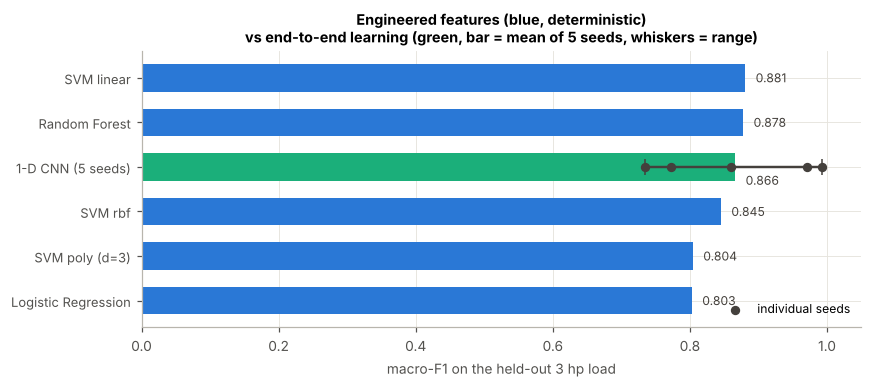

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
c = cmp.sort_values("macro_F1")
colours = [LOC_HUE["Outer"] if "CNN" in m else LOC_HUE["Ball"] for m in c.model]
ax.barh(range(len(c)), c.macro_F1, color=colours, height=0.62)
cnn_i = list(c.model).index("1-D CNN (5 seeds)")
ax.errorbar(cnn_mean, cnn_i, xerr=[[cnn_mean - cnn_lo], [cnn_hi - cnn_mean]],
            fmt="none", ecolor=INK, elinewidth=1.6, capsize=5, zorder=5)
ax.scatter(stab.test_macroF1, [cnn_i] * len(stab), s=26, color=INK, zorder=6,
           label="individual seeds")
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.model, fontsize=8.5)
ax.set_xlabel("macro-F1 on the held-out 3 hp load"); ax.set_xlim(0, 1.05)
for i, v in enumerate(c.macro_F1):
    ax.text(v + 0.015, i - 0.3 if i == cnn_i else i, f"{v:.3f}", va="center",
            fontsize=8, color=INK)
ax.set_title("Engineered features (blue, deterministic)\nvs end-to-end learning "
             "(green, bar = mean of 5 seeds, whiskers = range)", fontsize=9.5)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("figures/ii3_comparison.png"); plt.show()

**What this says.** The honest reading is not "the SVM beat the CNN". The CNN's five seeds
straddle the Part I result: some land above the best SVM and some well below it, and the
spread between them is larger than the gap between the two methods' averages. What the
experiment does establish is a difference in **reliability**. Refit the linear SVM and you
get the same classifier; retrain the CNN and you may get 0.73 or 0.99, with the validation
set reporting a flawless 1.000 either way. For a condition-monitoring system that will be
retrained whenever new data arrives, that instability is a more serious objection than a
few points of average accuracy.

The cause is visible in the per-class table: the errors are concentrated in decisions that
are close to ties: `Ball_021` against `Ball_014`, and `Inner_014` against everything. The
validation load contains nothing that distinguishes a model that gets those right from one
that gets them wrong, so early stopping cannot select between them and the outcome is left
to initialisation.

<a id="task-ii4"></a>
---
## Task II.4 — Model Behaviour

**Investigation chosen: A — Model Complexity.**

We vary one architectural parameter, the number of filters in the first convolutional
layer, across **8, 16, 32 and 64**, leaving everything else fixed. Every setting is trained
with three seeds (42, 1, 7) and reported as mean ± standard deviation; the runs at the
baseline width of 16 are reused from II.3.1 rather than repeated.

Section II.3.1 already established the measuring stick. A difference between widths counts
only if it is larger than the difference between runs of the *same* width, and that
within-setting spread was 0.24 macro-F1, so the bar is high.

In [12]:
FILTER_GRID = [8, 16, 32, 64]
SEEDS = [42, 1, 7]
BASELINE_FILTERS = 16

runs = []
t_all = time.time()
for f1_filters in FILTER_GRID:
    for s in SEEDS:
        if f1_filters == BASELINE_FILTERS:
            # already trained in II.3.1 on these seeds -- reuse rather than repeat
            r = stab[stab.seed == s].iloc[0]
            runs.append(dict(filters=f1_filters, seed=s, params=n_train,
                             epochs=int(r.epochs), val_acc=float(r.val_acc),
                             test_acc=float(r.test_acc),
                             test_macroF1=float(r.test_macroF1), secs=float(r.secs),
                             source="reused from II.3.1"))
        else:
            m = build_cnn(filters1=f1_filters, seed=s)
            h, secs = train_cnn(m, seed=s)
            p = m.predict(Xte, verbose=0).argmax(1)
            runs.append(dict(
                filters=f1_filters, seed=s,
                params=int(sum(np.prod(w.shape) for w in m.trainable_weights)),
                epochs=len(h.history["loss"]), val_acc=max(h.history["val_accuracy"]),
                test_acc=(p == yte).mean(),
                test_macroF1=f1_score(yte, p, average="macro"),
                secs=round(secs, 1), source="trained here"))
        print(f"  filters={f1_filters:<3} seed={s:<3} "
              f"epochs={runs[-1]['epochs']:<4} "
              f"test macro-F1 {runs[-1]['test_macroF1']:.4f}   {runs[-1]['source']}")
runs = pd.DataFrame(runs)
runs.to_csv("results/part2_capacity_study.csv", index=False)
print(f"\n{len(runs)} runs ({(runs.source=='trained here').sum()} newly trained) "
      f"in {(time.time()-t_all)/60:.1f} min")

  filters=8   seed=42  epochs=44   test macro-F1 0.8628   trained here


  filters=8   seed=1   epochs=57   test macro-F1 0.9371   trained here


  filters=8   seed=7   epochs=60   test macro-F1 0.9338   trained here
  filters=16  seed=42  epochs=79   test macro-F1 0.7345   reused from II.3.1
  filters=16  seed=1   epochs=85   test macro-F1 0.9713   reused from II.3.1
  filters=16  seed=7   epochs=86   test macro-F1 0.8605   reused from II.3.1


  filters=32  seed=42  epochs=83   test macro-F1 0.8955   trained here


  filters=32  seed=1   epochs=77   test macro-F1 0.9651   trained here


  filters=32  seed=7   epochs=65   test macro-F1 0.9879   trained here


  filters=64  seed=42  epochs=50   test macro-F1 0.7444   trained here


  filters=64  seed=1   epochs=88   test macro-F1 0.7489   trained here


  filters=64  seed=7   epochs=108  test macro-F1 0.8971   trained here

12 runs (9 newly trained) in 5.5 min


In [13]:
agg = runs.groupby("filters").agg(
    params=("params", "first"),
    mean_F1=("test_macroF1", "mean"), std_F1=("test_macroF1", "std"),
    min_F1=("test_macroF1", "min"), max_F1=("test_macroF1", "max"),
    mean_epochs=("epochs", "mean")).round(4)
print("Test macro-F1 by first-layer width, over 3 seeds\n")
print(agg.to_string())

spread_within = runs.groupby("filters").test_macroF1.apply(lambda v: v.max() - v.min()).max()
spread_between = agg.mean_F1.max() - agg.mean_F1.min()
print(f"\nlargest spread BETWEEN settings (means) : {spread_between:.4f}")
print(f"largest spread WITHIN a setting (seeds) : {spread_within:.4f}")
print("\n" + ("The between-setting difference is smaller than the seed-to-seed spread,\n"
              "so it cannot be attributed to capacity."
              if spread_between <= spread_within else
              "The between-setting difference exceeds the seed-to-seed spread,\n"
              "so capacity does have an effect beyond random initialisation."))

Test macro-F1 by first-layer width, over 3 seeds

         params  mean_F1  std_F1  min_F1  max_F1  mean_epochs
filters                                                      
8          4162   0.9113  0.0420  0.8628  0.9371      53.6667
16         5466   0.8555  0.1185  0.7345  0.9713      83.3333
32         8074   0.9495  0.0482  0.8955  0.9879      75.0000
64        13290   0.7968  0.0869  0.7444  0.8971      82.0000

largest spread BETWEEN settings (means) : 0.1527
largest spread WITHIN a setting (seeds) : 0.2368

The between-setting difference is smaller than the seed-to-seed spread,
so it cannot be attributed to capacity.


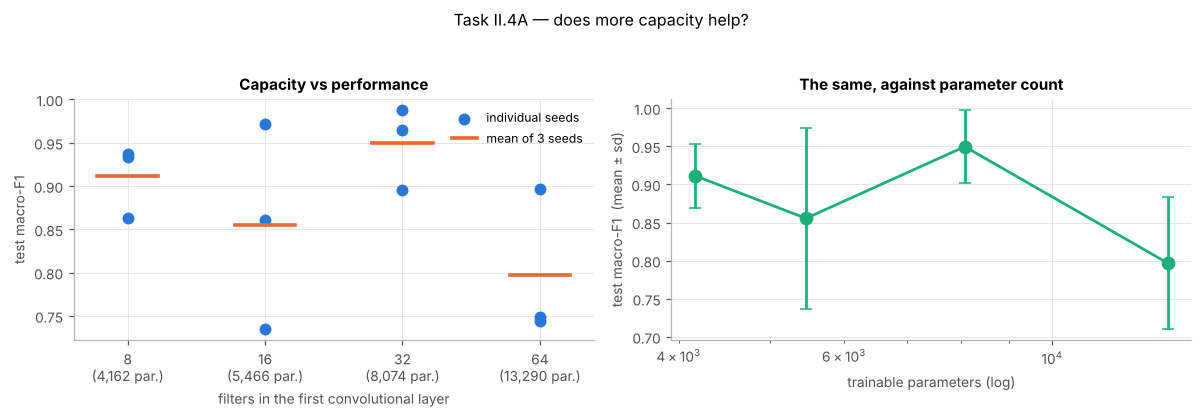

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for i, f_ in enumerate(FILTER_GRID):
    v = runs[runs.filters == f_].test_macroF1
    ax.scatter([i] * len(v), v, s=46, color=LOC_HUE["Ball"], zorder=3,
               label="individual seeds" if i == 0 else None)
    ax.plot([i - 0.22, i + 0.22], [v.mean()] * 2, color=LOC_HUE["Inner"], lw=2.4,
            zorder=4, label="mean of 3 seeds" if i == 0 else None)
ax.set_xticks(range(len(FILTER_GRID)))
ax.set_xticklabels([f"{f_}\n({agg.loc[f_,'params']:,} par.)" for f_ in FILTER_GRID])
ax.set_xlabel("filters in the first convolutional layer")
ax.set_ylabel("test macro-F1"); ax.set_title("Capacity vs performance")
ax.legend(fontsize=8)

ax = axes[1]
ax.errorbar(agg.params, agg.mean_F1, yerr=agg.std_F1, fmt="o-", color=LOC_HUE["Outer"],
            lw=1.8, ms=8, capsize=4)
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (log)")
ax.set_ylabel("test macro-F1  (mean ± sd)")
ax.set_title("The same, against parameter count")
plt.suptitle("Task II.4A — does more capacity help?", y=1.04, fontsize=10.5)
plt.tight_layout(); plt.savefig("figures/ii4_capacity.png"); plt.show()

### What the capacity study shows

**Nothing about capacity, and that is the finding.** Widening the first convolutional layer
from 8 to 64 filters triples the parameter count, from 4,162 to 13,290, and moves the mean
test macro-F1 around by about 0.15. But the spread between seeds at a *single* width is
larger than that. The widths cannot be ranked on this evidence, and any claim that one of
them is "the best architecture" would be a claim about which random initialisations
happened to be drawn.

This is precisely the situation the assignment's wording anticipates, and the honest
conclusion is the negative one: **on this dataset the observed differences between
architectures are within the range produced by random initialisation alone.** Reporting
the best run of each setting, which is what a single-seed comparison effectively does,
would have produced a confident and entirely spurious ranking.

Three things follow for how this model would have to be built in practice:

1. **Any architecture choice needs repeated runs**, and more than three. With a
   within-setting spread of 0.24, distinguishing two architectures that genuinely differ by
   0.05 would need on the order of tens of runs per setting.
2. **The instability has a cause that is fixable in principle.** The validation load scores
   1.000 for every run, so early stopping has no signal with which to prefer a model that
   gets the `Ball_021` / `Ball_014` tie right over one that does not. A validation set that
   contained a genuinely difficult operating point would restore that signal.
3. **Averaging the seeds would help.** An ensemble of the five runs, or simply reporting the
   mean, is a far more stable estimator than any individual network, at five times the
   training cost, which here is still only a few minutes.

<a id="supplement"></a>
---
# Supplement: the MOD550 CNN lab, applied to the same data

Tasks II.1 to II.4 above answer the assignment. This supplement works through **every
technique taught in the MOD550 CNN lab, one at a time, on the same bearing windows**, so that
each lecture idea is shown on our own measurements rather than on MNIST or CIFAR-10. The
windows, the split and the network family are the ones used above.

**How it relates to Tasks II.1 to II.4**

- **It sits after Task II.4 on purpose.** Where a model here stops early, it stops on the 2 hp
  validation loss, never on the test load. Test-load numbers appear only to show what each lab idea does, and
  nothing here is used to choose an architecture.
- **It is outside the word-limited reports** and changes no number reported in Tasks II.1
  to II.4.
- **The models here follow the lab recipe, so they are not interchangeable with Task II.3's.**
  They are trained without `class_weight`, because Part I's A8 found that class weighting
  costs the RBF SVM about 0.06 macro-F1 on this data. A single-seed comparison of the two
  recipes is in C10; Task II.3.1 explains why a single seed is weak evidence.
- **C9 argues against a lab idiom, not against a task.** Task II.3 validates on a held-out
  motor load, which is exactly why it avoids the `validation_split` trap C9 measures.
- The SVM lab's methods are in the matching supplement of `Part_I_SVM.ipynb`.

| Section | Source | Method | Extends |
|---|---|---|---|
| C1 | `01_mnist_cnn.py` | always look at the data first | II.2.1 |
| C2 | CNN lab slide 3 | why not just a dense network | II.2.2 |
| C3 | CNN lab slide 4, `CNN-example.py` | convolution, what a kernel actually does | II.2.2 |
| C4 | CNN lab slides 7 and 9 | padding, stride, the output-shape formula | II.2.2 |
| C5 | CNN lab slide 8 | what a parameter is, counted by hand | II.2.2 |
| C6 | CNN lab slide 20 | pooling pays for itself | II.2.2 |
| C7 | CNN lab slide 10 | the shape of the whole network | II.2.2 |
| C8 | CNN lab slides 13 to 14 | one-hot against integer labels | II.3 |
| C9 | CNN lab slide 15 | the training knobs, and why `validation_split` lies here | II.3 |
| C10 | `02_mnist_confusion.py` | the confusion matrix and the worst confusions | II.3 |
| C11 | `03_cifar_cnn.py` | augmentation and dropout | II.4 |
| C12 | `01_mnist_cnn.py` | save the model, load it back | II.4 |
| C13 | `05_predict_photo.py`, `prepare_photo.py` | one brand new measurement, end to end | II.4 |


## C1. Always look at the data first

*Extends Task II.2.1.*

*`01_mnist_cnn.py`: the four lines, every single time.* The MNIST script prints the
shapes and the class counts and plots one example of each class. Transposed to a 1-D
signal, "one example of each class" is the waveform plot in A1, so here we add the
checks the lab lists underneath it: *are the values in the range the model expects?*

In [15]:
print("train:", Xtr.shape, " test:", Xte.shape)
print("how many of each class:", np.bincount(ytr))
print(f"\nvalue range after scaling: [{Xtr.min():.2f}, {Xtr.max():.2f}]  "
      f"mean {Xtr.mean():+.3f}  std {Xtr.std():.3f}")
print(f"test set                 : [{Xte.min():.2f}, {Xte.max():.2f}]  "
      f"mean {Xte.mean():+.3f}  std {Xte.std():.3f}")
print("""
The lab's list of what this catches: images loaded upside down, labels shifted by one,
colour channels in the wrong order, a class with almost no examples, pixels still in
0-255 instead of 0-1. The vibration equivalents are: a signal read at the wrong
sampling rate (caught in Part I Task I.2.2), a channel read from the wrong record
(caught in Part I Task I.2.3), and amplitudes left unscaled. All three happened.""")

train: (1622, 2048, 1)  test: (827, 2048, 1)
how many of each class: [ 88 118 118 118 118 118 118 354 118 354]

value range after scaling: [-16.47, 17.03]  mean -0.000  std 1.000
test set                 : [-17.09, 17.03]  mean -0.017  std 0.951

The lab's list of what this catches: images loaded upside down, labels shifted by one,
colour channels in the wrong order, a class with almost no examples, pixels still in
0-255 instead of 0-1. The vibration equivalents are: a signal read at the wrong
sampling rate (caught in Part I Task I.2.2), a channel read from the wrong record
(caught in Part I Task I.2.3), and amplitudes left unscaled. All three happened.


## C2. Why not just a dense network?

*Extends Task II.2.2.*

*CNN lab slide 3: "A 28 x 28 image flattened is 784 numbers. One dense layer of 128
neurons already costs 100 480 weights."* Our window is 2048 numbers, so the argument is
nearly three times stronger.

In [16]:
n_in, dense_units = WINDOW, 128
dense_cost = n_in * dense_units + dense_units
print(f"a {n_in}-sample window into one Dense({dense_units}) layer:")
print(f"    {n_in} x {dense_units} + {dense_units} = {dense_cost:,} weights")
print(f"    (the lab's 28x28 image needed {784*128+128:,})")
print(f"\none Conv1D(16, kernel=64) layer instead:")
print(f"    (64 x 1 + 1) x 16 = {(64*1+1)*16:,} weights, reused at every position")
print(f"\nratio: {dense_cost / ((64*1+1)*16):,.0f} times fewer parameters")
print("""
Reason 2 from the lab, geometry is lost: flattening says sample 900 and sample 901 are
just inputs 900 and 901. For vibration that is worse than for an image, because the
entire diagnostic content is the SPACING between impacts. A dense layer would have to
learn that spacing separately at every possible offset; a convolution learns it once.""")

a 2048-sample window into one Dense(128) layer:
    2048 x 128 + 128 = 262,272 weights
    (the lab's 28x28 image needed 100,480)

one Conv1D(16, kernel=64) layer instead:
    (64 x 1 + 1) x 16 = 1,040 weights, reused at every position

ratio: 252 times fewer parameters

Reason 2 from the lab, geometry is lost: flattening says sample 900 and sample 901 are
just inputs 900 and 901. For vibration that is worse than for an image, because the
entire diagnostic content is the SPACING between impacts. A dense layer would have to
learn that spacing separately at every possible offset; a convolution learns it once.


## C3. Convolution: what a kernel actually does

*Extends Task II.2.2.*

*CNN lab slide 4, and `CNN-example.py`, which builds a 5x5 digit by hand and runs a
single 2x2 kernel over it so you can see the feature map.* The lab's figure shows one
image and three kernels: a vertical edge detector, a horizontal one, and a blur. In 1-D
the three natural equivalents are a step detector, a smoother, and a differentiator.

**In a CNN you never choose these numbers; training finds them.** This cell is only to
see what the operation does.

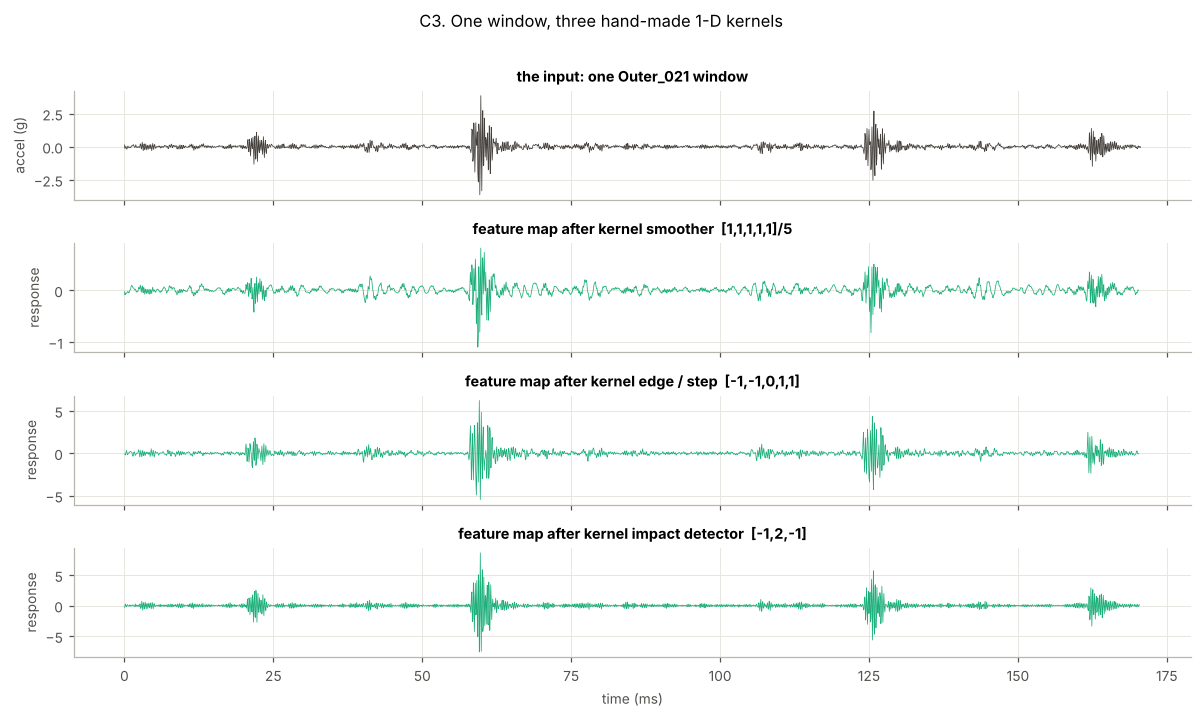

kernel                          out len  kurtosis  vs input
------------------------------------------------------------
(the input itself)                 2048     36.55          
smoother  [1,1,1,1,1]/5            2044     20.43    -16.12
edge / step  [-1,-1,0,1,1]         2044     29.17     -7.38
impact detector  [-1,2,-1]         2046     37.15     +0.60

Output length is always 2048 - k + 1, the padding="valid" formula from slide 9.

Kurtosis measures impulsiveness, which is the quantity bearing diagnostics cares about.
The smoother destroys it (20.4 against 36.6): averaging five neighbouring samples
blunts exactly the sharp transients a spall produces. The two differencing kernels keep
or slightly raise it, because differencing suppresses the smooth background and leaves
the discontinuities behind.

That is the whole intuition for why a convolution suits this signal, and why the first
layer of II.2.2 uses a 64-sample kernel: wide enough to hold one transient, so a filter
can lear

In [17]:
win = X[(y == CLASSES.index("Outer_021")) & (meta["load"] == 1)][0]
KERNELS = {
    "smoother  [1,1,1,1,1]/5": np.ones(5) / 5,
    "edge / step  [-1,-1,0,1,1]": np.array([-1, -1, 0, 1, 1.0]),
    "impact detector  [-1,2,-1]": np.array([-1, 2, -1.0]),
}
fig, axes = plt.subplots(4, 1, figsize=(11, 6.4), sharex=True)
axes[0].plot(np.arange(WINDOW) / FS * 1000, win, lw=0.5, color=INK)
axes[0].set_title("the input: one Outer_021 window", fontsize=9.5)
axes[0].set_ylabel("accel (g)")
for ax, (nm, k) in zip(axes[1:], KERNELS.items()):
    fmap = np.convolve(win, k[::-1], mode="valid")
    ax.plot(np.arange(len(fmap)) / FS * 1000, fmap, lw=0.5, color=LOC_HUE["Outer"])
    ax.set_title(f"feature map after kernel {nm}", fontsize=9.5)
    ax.set_ylabel("response")
axes[-1].set_xlabel("time (ms)")
plt.suptitle("C3. One window, three hand-made 1-D kernels", y=1.01)
plt.tight_layout(); plt.savefig("figures/ii_lab_c3_kernels.png"); plt.show()

k0 = float(pd.Series(win).kurt())
print(f"{'kernel':<30}{'out len':>9}{'kurtosis':>10}{'vs input':>10}")
print("-" * 60)
print(f"{'(the input itself)':<30}{WINDOW:>9}{k0:>10.2f}{'':>10}")
for nm, k in KERNELS.items():
    fmap = np.convolve(win, k[::-1], mode="valid")
    kk = float(pd.Series(fmap).kurt())
    print(f"{nm:<30}{len(fmap):>9}{kk:>10.2f}{kk - k0:>+10.2f}")
print(f"""
Output length is always {WINDOW} - k + 1, the padding="valid" formula from slide 9.

Kurtosis measures impulsiveness, which is the quantity bearing diagnostics cares about.
The smoother destroys it ({float(pd.Series(np.convolve(win, KERNELS['smoother  [1,1,1,1,1]/5'][::-1], mode='valid')).kurt()):.1f} against {k0:.1f}): averaging five neighbouring samples
blunts exactly the sharp transients a spall produces. The two differencing kernels keep
or slightly raise it, because differencing suppresses the smooth background and leaves
the discontinuities behind.

That is the whole intuition for why a convolution suits this signal, and why the first
layer of II.2.2 uses a 64-sample kernel: wide enough to hold one transient, so a filter
can learn its shape rather than just its presence. In a real CNN nobody chooses these
numbers; training finds them.""")

## C4. Padding, stride, and where the output shape comes from

*Extends Task II.2.2.*

*CNN lab slides 7 and 9.* The formula

$$n_{out} \;=\; \frac{n_{in} + 2p - k}{s} + 1$$

answers "why 26?" for MNIST. Here it answers why our first layer turns 2048 into 249.

In [18]:
def out_len(n_in, k, s=1, p=0):
    return (n_in + 2 * p - k) // s + 1


print(f"{'layer':<34}{'formula':<30}{'out'}")
print("-" * 76)
print(f"{'Conv1D(16, k=64, s=8, valid)':<34}{'(2048 + 0 - 64)/8 + 1':<30}{out_len(2048,64,8)}")
print(f"{'MaxPooling1D(2)':<34}{'249 // 2':<30}{249//2}")
print(f"{'Conv1D(32, k=3, same)':<34}{'(124 + 2 - 3)/1 + 1':<30}{out_len(124,3,1,1)}")
print(f"{'MaxPooling1D(2)':<34}{'124 // 2':<30}{124//2}")
print(f"{'GlobalAveragePooling1D':<34}{'collapses the time axis':<30}{'1 x 32'}")
print(f"""
padding="valid" against padding="same", on our numbers:
  valid, k=3 on 124 steps -> {out_len(124,3,1,0)} steps, one sample lost at each edge
  same,  k=3 on 124 steps -> {out_len(124,3,1,1)} steps, a zero added at each edge first

We use valid for the wide first kernel and same for the narrow second one, which is the
CIFAR script's choice: shrink deliberately with pooling, not accidentally at the edges.""")

layer                             formula                       out
----------------------------------------------------------------------------
Conv1D(16, k=64, s=8, valid)      (2048 + 0 - 64)/8 + 1         249
MaxPooling1D(2)                   249 // 2                      124
Conv1D(32, k=3, same)             (124 + 2 - 3)/1 + 1           124
MaxPooling1D(2)                   124 // 2                      62
GlobalAveragePooling1D            collapses the time axis       1 x 32

padding="valid" against padding="same", on our numbers:
  valid, k=3 on 124 steps -> 122 steps, one sample lost at each edge
  same,  k=3 on 124 steps -> 124 steps, a zero added at each edge first

We use valid for the wide first kernel and same for the narrow second one, which is the
CIFAR script's choice: shrink deliberately with pooling, not accidentally at the edges.


## C5. What is a parameter, counted by hand

*Extends Task II.2.2.*

*CNN lab slide 8: a parameter is one single number that training is allowed to change.*
The general formula for a convolution is $(k \cdot C_{in} + 1) \cdot C_{out}$. We count
the whole network by hand and then compare with Keras's own count (the full
`model.summary()` table is printed in II.2.2).

In [19]:
def build_cnn_lab(filters1=16, filters2=32, kernel1=64, stride1=8, dense=64,
              dropout=0.3, pooling=True, augment=False, seed=SEED):
    """The II.2.2 architecture, with two flags (pooling, augment) added so C6 and C11 can
    vary one thing. With the flags at their defaults it is identical to build_cnn above."""
    keras.utils.set_random_seed(seed)
    L = [keras.Input(shape=(WINDOW, 1), name="raw_window")]
    if augment:
        L.append(RandomVibrationShift(name="augment"))
    L += [layers.Conv1D(filters1, kernel1, strides=stride1, activation="relu",
                        padding="valid", name="conv_wide"),
          layers.BatchNormalization(name="bn_1")]
    if pooling:
        L.append(layers.MaxPooling1D(2, name="pool_1"))
    L += [layers.Conv1D(filters2, 3, activation="relu", padding="same",
                        name="conv_narrow"),
          layers.BatchNormalization(name="bn_2")]
    if pooling:
        L.append(layers.MaxPooling1D(2, name="pool_2"))
    L += [layers.GlobalAveragePooling1D(name="aggregate_over_time"),
          layers.Dense(dense, activation="relu", name="hidden"),
          layers.Dropout(dropout, seed=seed, name="dropout"),
          layers.Dense(len(CLASSES), activation="softmax", name="class_scores")]
    return keras.Sequential(L, name="bearing_cnn_1d")


@keras.utils.register_keras_serializable()
class RandomVibrationShift(layers.Layer):
    """Training-only augmentation: circular time shift, amplitude jitter, sign flip."""

    def call(self, x, training=None):
        if not training:
            return x
        b = tf.shape(x)[0]
        shift = tf.random.uniform([], 0, WINDOW, dtype=tf.int32)
        x = tf.roll(x, shift=shift, axis=1)
        gain = tf.random.uniform([b, 1, 1], 0.9, 1.1)
        sign = tf.where(tf.random.uniform([b, 1, 1]) < 0.5, -1.0, 1.0)
        return x * gain * sign


lab_arch = build_cnn_lab()
assert lab_arch.count_params() == build_cnn().count_params(), "flags changed the architecture"
by_hand = {
    "conv_wide   (64*1+1)*16": (64 * 1 + 1) * 16,
    "bn_1        4*16": 4 * 16,
    "conv_narrow (3*16+1)*32": (3 * 16 + 1) * 32,
    "bn_2        4*32": 4 * 32,
    "hidden      32*64+64": 32 * 64 + 64,
    "class_scores 64*10+10": 64 * 10 + 10,
}
print("counted by hand\n")
for k, v in by_hand.items():
    print(f"  {k:<28}{v:>8,}")
print(f"  {'TOTAL':<28}{sum(by_hand.values()):>8,}")
total_keras = int(sum(np.prod(w.shape) for w in lab_arch.weights))
train_keras = int(sum(np.prod(w.shape) for w in lab_arch.trainable_weights))
print(f"\nkeras: {total_keras:,} total, {train_keras:,} trainable "
      f"({total_keras - train_keras:,} are the BatchNorm moving mean/variance, "
      f"which are updated but not trained)")
# (Keras's full summary table is printed in II.2.2)

counted by hand

  conv_wide   (64*1+1)*16        1,040
  bn_1        4*16                  64
  conv_narrow (3*16+1)*32        1,568
  bn_2        4*32                 128
  hidden      32*64+64           2,112
  class_scores 64*10+10            650
  TOTAL                          5,562

keras: 5,562 total, 5,466 trainable (96 are the BatchNorm moving mean/variance, which are updated but not trained)


## C6. Pooling pays for itself

*Extends Task II.2.2.*

*CNN lab slide 20: the same model without the two pooling layers is "21 times bigger, for
the same job".* We repeat that table. Our saving is smaller than the lab's, and the
reason is instructive.

In [20]:
pool_rows = []
for pooling in [True, False]:
    for agg, use_gap in [("GlobalAveragePooling1D", True), ("Flatten", False)]:
        keras.utils.set_random_seed(SEED)
        L = [keras.Input(shape=(WINDOW, 1)),
             layers.Conv1D(16, 64, strides=8, activation="relu", padding="valid")]
        if pooling:
            L.append(layers.MaxPooling1D(2))
        L.append(layers.Conv1D(32, 3, activation="relu", padding="same"))
        if pooling:
            L.append(layers.MaxPooling1D(2))
        L.append(layers.GlobalAveragePooling1D() if use_gap else layers.Flatten())
        L += [layers.Dense(64, activation="relu"), layers.Dense(10, activation="softmax")]
        m = keras.Sequential(L)
        pool_rows.append(dict(pooling=pooling, aggregation=agg,
                         into_dense=int(m.layers[-3].output.shape[-1]),
                         parameters=int(sum(np.prod(w.shape) for w in m.weights))))
tab = pd.DataFrame(pool_rows)
print(tab.to_string(index=False))
f_p = int(tab.query("aggregation=='Flatten' and pooling").parameters.iloc[0])
f_np = int(tab.query("aggregation=='Flatten' and not pooling").parameters.iloc[0])
g_p = int(tab.query("aggregation!='Flatten' and pooling").parameters.iloc[0])
g_np = int(tab.query("aggregation!='Flatten' and not pooling").parameters.iloc[0])
print(f"""
With Flatten, removing the two pooling layers takes the model from {f_p:,} parameters
to {f_np:,}, a factor of {f_np/f_p:.1f}. That is the lab's point: its MNIST model grew 21x
the same way. With GlobalAveragePooling1D it costs nothing at all ({g_p:,} either way), because
global pooling already collapses the time axis to one number per filter: the dense layer
reads 32 inputs whether the signal was 124 steps long or 1984.

That is why II.2.2 uses global pooling rather than Flatten. The lab's MNIST model
reaches Dense through 800 flattened numbers; ours would reach it through 1984, and the
dense layer alone would cost {1984*64+64:,} parameters for 1622 training windows.""")

 pooling            aggregation  into_dense  parameters
    True GlobalAveragePooling1D          32        5370
    True                Flatten        1984      130298
   False GlobalAveragePooling1D          32        5370
   False                Flatten        7968      513274

With Flatten, removing the two pooling layers takes the model from 130,298 parameters
to 513,274, a factor of 3.9. That is the lab's point: its MNIST model grew 21x
the same way. With GlobalAveragePooling1D it costs nothing at all (5,370 either way), because
global pooling already collapses the time axis to one number per filter: the dense layer
reads 32 inputs whether the signal was 124 steps long or 1984.

That is why II.2.2 uses global pooling rather than Flatten. The lab's MNIST model
reaches Dense through 800 flattened numbers; ours would reach it through 1984, and the
dense layer alone would cost 127,040 parameters for 1622 training windows.


## C7. The shape of the whole network

*Extends Task II.2.2.*

*CNN lab slide 10: "The image gets smaller and deeper as it moves right."*

In [21]:
print(f"{'layer':<24}{'output shape':<20}{'params':>10}")
print("-" * 56)
print(f"{'input':<24}{'(2048, 1)':<20}{0:>10}")
for lyr in lab_arch.layers:
    shp = str(tuple(lyr.output.shape[1:]))
    print(f"{lyr.name:<24}{shp:<20}{lyr.count_params():>10,}")
print("""
        window  ->  conv_wide  ->  pool  ->  conv_narrow  ->  pool  ->  GAP  ->  dense
       2048 x 1      249 x 16    124 x 16      124 x 32      62 x 32     32      10

        |------------- feature extraction -------------|  |--- classification ---|

Shorter and deeper as it moves right, exactly as the lab draws it. Global pooling is
where the signal stops being a signal.""")

layer                   output shape            params
--------------------------------------------------------
input                   (2048, 1)                    0
conv_wide               (249, 16)                1,040
bn_1                    (249, 16)                   64
pool_1                  (124, 16)                    0
conv_narrow             (124, 32)                1,568
bn_2                    (124, 32)                  128
pool_2                  (62, 32)                     0
aggregate_over_time     (32,)                        0
hidden                  (64,)                    2,112
dropout                 (64,)                        0
class_scores            (10,)                      650

        window  ->  conv_wide  ->  pool  ->  conv_narrow  ->  pool  ->  GAP  ->  dense
       2048 x 1      249 x 16    124 x 16      124 x 32      62 x 32     32      10

        |------------- feature extraction -------------|  |--- classification ---|

Shorter and deeper as it m

## C8. One-hot against integer labels

*Extends Task II.3.*

*CNN lab slides 13 and 14: "Identical maths, sparse just converts for you."* Case 1 of
the lab used `to_categorical` with `categorical_crossentropy`; case 2 kept integers and
used `sparse_categorical_crossentropy`. We run both on the bearing data, same seed, and
check the claim.

In [22]:
from tensorflow.keras.utils import to_categorical

EPOCHS_DEMO = 12
ytr_1hot, yva_1hot = to_categorical(ytr, 10), to_categorical(yva, 10)
print("3 -> ", to_categorical([3], 10)[0].astype(int), "   (what to_categorical does)\n")

demo = {}
for nm, loss, Ytr, Yva in [
        ("integers + sparse_categorical_crossentropy",
         "sparse_categorical_crossentropy", ytr, yva),
        ("one-hot  + categorical_crossentropy",
         "categorical_crossentropy", ytr_1hot, yva_1hot)]:
    m = build_cnn_lab(seed=SEED)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss=loss, metrics=["accuracy"])
    h = m.fit(Xtr, Ytr, validation_data=(Xva, Yva), epochs=EPOCHS_DEMO,
              batch_size=64, verbose=0, shuffle=True)
    demo[nm] = (h.history["loss"][-1], h.history["accuracy"][-1],
                h.history["val_accuracy"][-1])
    print(f"{nm:<46} final loss {demo[nm][0]:.6f}  "
          f"train acc {demo[nm][1]:.4f}  val acc {demo[nm][2]:.4f}")
a, b = list(demo.values())
print(f"\nloss differs by {abs(a[0]-b[0]):.2e}: the same maths, reached by the same route.")
print("The label format decides the word 'sparse', and nothing else.")

3 ->  [0 0 0 1 0 0 0 0 0 0]    (what to_categorical does)



integers + sparse_categorical_crossentropy     final loss 0.071587  train acc 0.9920  val acc 0.8426


one-hot  + categorical_crossentropy            final loss 0.071587  train acc 0.9920  val acc 0.8426

loss differs by 0.00e+00: the same maths, reached by the same route.
The label format decides the word 'sparse', and nothing else.


## C9. The training knobs, and why `validation_split` lies here

*Extends Task II.3: the stopping rule.*

*CNN lab slide 15: epochs, batch_size, validation_split. "The gap between training and
validation accuracy is the only reliable sign of overfitting."* Both lab scripts use
`validation_split=0.1`, which holds back a random 10% of the training data.

On MNIST that is correct. On our data it is the wine trick again, so this is the one
place where we deliberately depart from the lab script, and here is the measurement that
justifies it.

In [23]:
m_split = build_cnn_lab(seed=SEED)
m_split.compile(optimizer=keras.optimizers.Adam(1e-3),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_split = m_split.fit(Xtr, ytr, validation_split=0.1, epochs=EPOCHS_DEMO,
                      batch_size=64, verbose=0, shuffle=True)

# the same thing again, but with the training set shuffled first
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(ytr))
m_shuf = build_cnn_lab(seed=SEED)
m_shuf.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_shuf = m_shuf.fit(Xtr[perm], ytr[perm], validation_split=0.1, epochs=EPOCHS_DEMO,
                    batch_size=64, verbose=0, shuffle=True)

m_load = build_cnn_lab(seed=SEED)
m_load.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_load = m_load.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS_DEMO,
                    batch_size=64, verbose=0, shuffle=True)

tail = ytr[int(0.9 * len(ytr)):]
print(f"what validation_split=0.1 actually holds back, unshuffled: "
      f"{len(tail)} windows, classes {sorted(set(CLASSES[c] for c in tail))}\n")
print(f"{'validation scheme':<46}{'val acc':>9}{'test acc':>10}")
print("-" * 66)
for nm, h, m in [("validation_split=0.1, data in file order", h_split, m_split),
                 ("validation_split=0.1, shuffled first", h_shuf, m_shuf),
                 ("held-out motor load (ours)", h_load, m_load)]:
    te_acc = (m.predict(Xte, verbose=0).argmax(1) == yte).mean()
    print(f"{nm:<46}{h.history['val_accuracy'][-1]:>9.4f}{te_acc:>10.4f}")
print("""
Three schemes, three completely different validation numbers for models that are all
about equally good on the test load.

Row 1 is a trap the lab script would walk straight into. `validation_split` does NOT
take a random 10%: it takes the LAST 10%, before any shuffling. Our windows are built
recording by recording, so the last 10% is a single class. Validation accuracy 0.000,
and the early-stopping callback would be steering on noise.

Row 2 is the lab's intent: shuffle first, then hold back 10%. Now it reports a
flattering number, because those windows come from the same recordings the model just
trained on. It is measuring memory.

Row 3 is ours: a different operating point, sharing no recording with training. It is
the only one of the three whose number means anything, and even it overstates the test
load, which is the honest finding of II.3.""")

what validation_split=0.1 actually holds back, unshuffled: 163 windows, classes ['Outer_021']

validation scheme                               val acc  test acc
------------------------------------------------------------------


validation_split=0.1, data in file order         0.0000    0.6360


validation_split=0.1, shuffled first             0.6871    0.6433


held-out motor load (ours)                       0.8426    0.7219

Three schemes, three completely different validation numbers for models that are all
about equally good on the test load.

Row 1 is a trap the lab script would walk straight into. `validation_split` does NOT
take a random 10%: it takes the LAST 10%, before any shuffling. Our windows are built
recording by recording, so the last 10% is a single class. Validation accuracy 0.000,
and the early-stopping callback would be steering on noise.

Row 2 is the lab's intent: shuffle first, then hold back 10%. Now it reports a
flattering number, because those windows come from the same recordings the model just
trained on. It is measuring memory.

Row 3 is ours: a different operating point, sharing no recording with training. It is
the only one of the three whose number means anything, and even it overstates the test
load, which is the honest finding of II.3.


## C10. Train it, then find the worst confusions

*Extends Task II.3: the confusion matrix.*

*`02_mnist_confusion.py`* prints the confusion matrix, the classification report, and
then ranks the five worst confused pairs. That last loop is the most useful few lines in
the whole CNN lab, and it finds our problem immediately.

In [24]:
def train_lab(m, seed=SEED, verbose=0):
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                       restore_best_weights=True)
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS,
              batch_size=BATCH, callbacks=[cb], verbose=verbose, shuffle=True)
    return h, time.time() - t0


cnn_lab = build_cnn_lab(seed=SEED)
hist_lab, secs_lab = train_lab(cnn_lab)
pred_lab = cnn_lab.predict(Xte, verbose=0).argmax(1)
print(f"trained {len(hist_lab.history['loss'])} epochs in {secs_lab:.0f}s   "
      f"test accuracy {(pred_lab == yte).mean():.4f}   "
      f"macro-F1 {f1_score(yte, pred_lab, average='macro'):.4f}\n")
print(classification_report(yte, pred_lab, target_names=CLASSES, digits=3, zero_division=0))

cm_lab = confusion_matrix(yte, pred_lab)
print(pd.DataFrame(cm_lab, index=CLASSES, columns=CLASSES).to_string())

work = cm_lab.copy()
np.fill_diagonal(work, 0)
print("\nworst confusions:")
for _ in range(5):
    i, j = np.unravel_index(work.argmax(), work.shape)
    if work[i, j] == 0:
        break
    print(f"  true {CLASSES[i]:<12} predicted as {CLASSES[j]:<12} {work[i, j]:>4} times")
    work[i, j] = 0
print("""
The MNIST lab expected its errors in pairs that share most of their strokes: 4 and 9,
3 and 5, 7 and 9. Ours cluster in pairs that share most of their vibration: the same
defect diameter on different surfaces, and neighbouring diameters on the same surface.
Part I Task I.2.6 predicted this from the raw statistics before any model was fitted.""")

trained 75 epochs in 31s   test accuracy 0.8597   macro-F1 0.7406

              precision    recall  f1-score   support

      Normal      1.000     1.000     1.000        59
    Ball_007      0.527     1.000     0.690        59
    Ball_014      0.500     1.000     0.667        59
    Ball_021      0.000     0.000     0.000        59
   Inner_007      0.984     1.000     0.992        60
   Inner_014      1.000     0.034     0.066        59
   Inner_021      1.000     1.000     1.000        59
   Outer_007      0.983     1.000     0.992       177
   Outer_014      1.000     1.000     1.000        59
   Outer_021      1.000     1.000     1.000       177

    accuracy                          0.860       827
   macro avg      0.799     0.803     0.741       827
weighted avg      0.854     0.860     0.814       827

           Normal  Ball_007  Ball_014  Ball_021  Inner_007  Inner_014  Inner_021  Outer_007  Outer_014  Outer_021
Normal         59         0         0         0          0  

In [25]:
# the one comparison that connects this recipe to Task II.3 (a single seed, so only a hint)
s42 = stab[stab.seed == 42].iloc[0]
print(f"seed 42, class-weighted, Task II.3.1   test macro-F1 {s42.test_macroF1:.4f}")
print(f"seed 42, lab recipe, unweighted        test macro-F1 {f1_score(yte, pred_lab, average='macro'):.4f}")
print(f"\nthe five seeds of Task II.3.1 spread over {stab.test_macroF1.min():.4f} to "
      f"{stab.test_macroF1.max():.4f}, so this single pair cannot say which recipe is better")


seed 42, class-weighted, Task II.3.1   test macro-F1 0.7345
seed 42, lab recipe, unweighted        test macro-F1 0.7406

the five seeds of Task II.3.1 spread over 0.7345 to 0.9932, so this single pair cannot say which recipe is better


## C11. Augmentation and dropout

*Extends Task II.4.*

*`03_cifar_cnn.py` adds two lines, `RandomFlip` and `Dropout(0.3)`, "because this model
has 282 250 parameters and would otherwise memorise the training photographs".* Ours has
5 466 parameters for 1 622 windows, so the same pressure applies.

A horizontal flip of a car is still a car. The vibration equivalents must also be
physically true of a bearing:

| Augmentation | Why it is legitimate here |
|---|---|
| circular time shift | the window boundary is arbitrary; a fault does not care when we started recording |
| amplitude jitter, 0.9 to 1.1 | sensor mounting and gain vary between installations |
| sign flip | an accelerometer mounted the other way round reports the opposite sign |

A time *reversal* would not be legitimate: it reverses the shaft direction. Following
II.3.1's lesson that one seed proves nothing, each setting gets three seeds.

In [26]:
AUG_SEEDS = [42, 1, 7]
aug_rows = []
for augment in [False, True]:
    for s in AUG_SEEDS:
        m = build_cnn_lab(augment=augment, seed=s)
        h, sec = train_lab(m, seed=s)
        p = m.predict(Xte, verbose=0).argmax(1)
        aug_rows.append(dict(augmented=augment, seed=s, epochs=len(h.history["loss"]),
                             val_acc=max(h.history["val_accuracy"]),
                             test_acc=(p == yte).mean(),
                             test_macroF1=f1_score(yte, p, average="macro"),
                             secs=round(sec)))
        print(f"  augment={str(augment):<5} seed={s:<3} "
              f"macro-F1 {aug_rows[-1]['test_macroF1']:.4f}  ({sec:.0f}s)")
aug = pd.DataFrame(aug_rows)
aug.to_csv("results/part2_augmentation.csv", index=False)

summ = aug.groupby("augmented").test_macroF1.agg(["mean", "std", "min", "max"]).round(4)
print("\n" + summ.to_string())
gap = summ.loc[True, "mean"] - summ.loc[False, "mean"]
widest = aug.groupby("augmented").test_macroF1.apply(lambda v: v.max() - v.min()).max()

a_on = aug.loc[aug.augmented, "test_macroF1"].to_numpy()
a_off = aug.loc[~aug.augmented, "test_macroF1"].to_numpy()
wins = int((a_on[:, None] > a_off[None, :]).sum())
pairs = a_on.size * a_off.size

print(f"\ndifference of means              {gap:+.4f}")
print(f"widest spread within one setting  {widest:.4f}")
print(f"pairwise: an augmented run beats an un-augmented one in {wins} of {pairs} comparisons")
print(f"""
The difference of means ({gap:+.3f}) is smaller than the spread between seeds of a single
setting ({widest:.3f}), so by the test II.3.1 established this is not yet evidence: the
ranges overlap, and three seeds cannot separate them.

But the direction is consistent. {wins} of {pairs} pairwise comparisons favour augmentation,
and with three seeds against three the strongest result obtainable is {pairs} of {pairs}, so this
is close to the most suggestive outcome the experiment could produce. The honest
statement is: promising, worth running with ten seeds before claiming anything, and
physically well motivated since the window boundary genuinely is arbitrary.""")

  augment=False seed=42  macro-F1 0.7406  (34s)


  augment=False seed=1   macro-F1 0.7808  (54s)


  augment=False seed=7   macro-F1 0.8679  (47s)


  augment=True  seed=42  macro-F1 0.9677  (31s)


  augment=True  seed=1   macro-F1 0.8369  (53s)


  augment=True  seed=7   macro-F1 0.9777  (33s)

             mean     std     min     max
augmented                                
False      0.7964  0.0651  0.7406  0.8679
True       0.9274  0.0786  0.8369  0.9777

difference of means              +0.1310
widest spread within one setting  0.1408
pairwise: an augmented run beats an un-augmented one in 8 of 9 comparisons

The difference of means (+0.131) is smaller than the spread between seeds of a single
setting (0.141), so by the test II.3.1 established this is not yet evidence: the
ranges overlap, and three seeds cannot separate them.

But the direction is consistent. 8 of 9 pairwise comparisons favour augmentation,
and with three seeds against three the strongest result obtainable is 9 of 9, so this
is close to the most suggestive outcome the experiment could produce. The honest
statement is: promising, worth running with ten seeds before claiming anything, and
physically well motivated since the window boundary genuinely is arbi

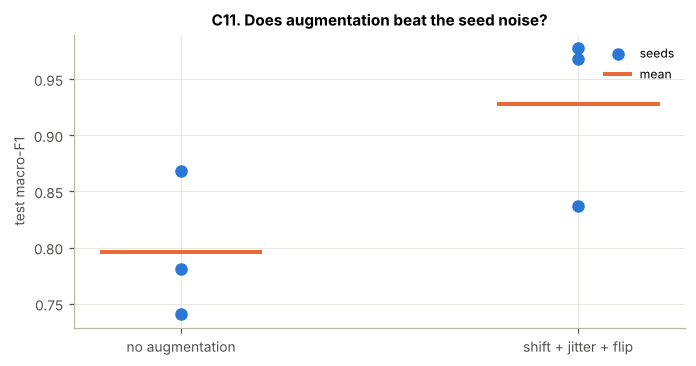

In [27]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for i, a in enumerate([False, True]):
    v = aug[aug.augmented == a].test_macroF1
    ax.scatter([i] * len(v), v, s=52, color=LOC_HUE["Ball"], zorder=3,
               label="seeds" if i == 0 else None)
    ax.plot([i - .2, i + .2], [v.mean()] * 2, lw=2.6, color=LOC_HUE["Inner"], zorder=4,
            label="mean" if i == 0 else None)
ax.set_xticks([0, 1]); ax.set_xticklabels(["no augmentation", "shift + jitter + flip"])
ax.set_ylabel("test macro-F1"); ax.set_title("C11. Does augmentation beat the seed noise?")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/ii_lab_c11_augmentation.png"); plt.show()

## C12. Save the model, load it back

*Extends Task II.4, and the deployment question of Question II.3.*

*`01_mnist_cnn.py` ends with `model.save("mnist_cnn.keras")`, and `02` and `05` load it
back.* Worth doing for real: a model you cannot reload is a model you cannot deploy, and
the check below is the one that catches a broken custom layer.

In [28]:
cnn_lab.save("models/bearing_cnn.keras")
size_kb = os.path.getsize("models/bearing_cnn.keras") / 1024
reloaded = keras.models.load_model("models/bearing_cnn.keras")
p_reload = reloaded.predict(Xte, verbose=0).argmax(1)
print(f"saved models/bearing_cnn.keras ({size_kb:.0f} KB)")
print(f"reloaded model gives identical predictions: {bool((p_reload == pred_lab).all())}")
print(f"agreement: {(p_reload == pred_lab).mean():.6f}")

saved models/bearing_cnn.keras (115 KB)
reloaded model gives identical predictions: True
agreement: 1.000000


## C13. One brand new measurement, end to end

*Extends Task II.4.*

*`prepare_photo.py` and `05_predict_photo.py`: "Write a digit on paper, photograph it,
and ask the model what it is. But the model only accepts 28 x 28 x 1."* The photo arrives
at the wrong size, the wrong polarity and the wrong framing, and the script fixes all
three before the model sees it.

The bearing equivalent of a phone photo is a vibration snippet from somewhere else: an
arbitrary length, possibly a different sampling rate, and an unknown sensor gain.
`prepare_window` below is the direct analogue of `prepare`.

source: IR_021_load3, 3000 raw samples at 12000 Hz, peak 2.55 g



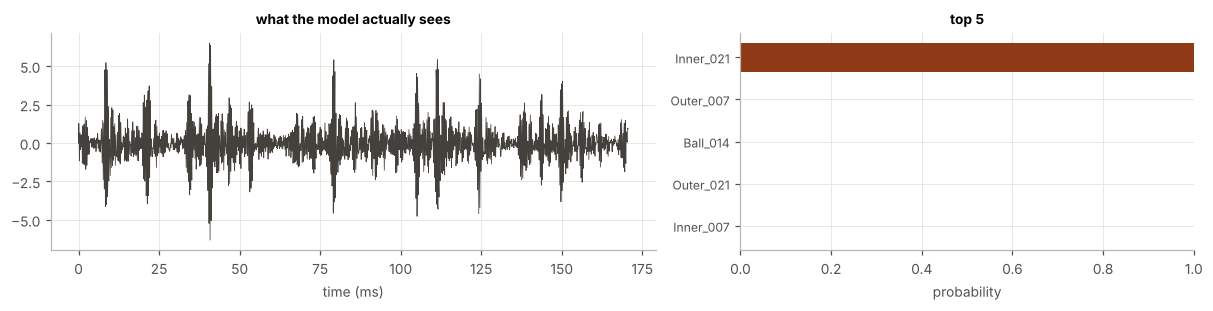

prediction: Inner_021
confidence: 100.0%
truth     : Inner_021   -> CORRECT

full breakdown:
  Inner_021    100.0%  #######################################
  Outer_007      0.0%  
  Ball_014       0.0%  
  Outer_021      0.0%  
  Inner_007      0.0%  
  Ball_007       0.0%  
  Ball_021       0.0%  
  Normal         0.0%  
  Inner_014      0.0%  
  Outer_014      0.0%  


In [29]:
from scipy.signal import resample_poly


def prepare_window(signal, fs_in, mu=mu, sd=sd, want=WINDOW):
    """Any raw vibration snippet -> the (1, 2048, 1) input the model accepts.

    Mirrors prepare_photo.prepare step for step:
      1. any length, any rate  -> resample to the 12 kHz the model was trained at
      2. wrong framing         -> take a centred window of exactly 2048 samples
      3. wrong overall level   -> remove the DC offset the mounting adds
      4. wrong scale           -> apply the TRAINING mean and std, never the new
                                  signal's own, or the amplitude information that
                                  distinguishes healthy from faulty is scaled away
      5. the shape it wants    -> (1, 2048, 1): a batch of one, one channel
    """
    x = np.asarray(signal, dtype=np.float64).ravel()
    if fs_in != FS:                                            # 1
        g = np.gcd(int(fs_in), int(FS))
        x = resample_poly(x, FS // g, int(fs_in) // g)
    if len(x) < want:                                          # 2
        x = np.pad(x, (0, want - len(x)))
    start = (len(x) - want) // 2
    x = x[start:start + want]
    x = x - x.mean()                                           # 3
    x = (x - mu) / sd                                          # 4
    return x.reshape(1, want, 1).astype("float32")             # 5


def report(x, true_label=None, title=""):
    """The lab's predict_photo output: look at it first, then read the confidence."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 2.9),
                             gridspec_kw={"width_ratios": [2, 1.5]})
    axes[0].plot(np.arange(WINDOW) / FS * 1000, x[0, :, 0], lw=0.5, color=INK)
    axes[0].set_title(f"what the model actually sees{title}", fontsize=9)
    axes[0].set_xlabel("time (ms)")
    p = cnn_lab.predict(x, verbose=0)[0]
    order = np.argsort(p)[::-1][:5]
    axes[1].barh(range(len(order)), p[order][::-1],
                 color=[class_colour(CLASSES[i]) for i in order][::-1], height=.68)
    axes[1].set_yticks(range(len(order)))
    axes[1].set_yticklabels([CLASSES[i] for i in order][::-1], fontsize=8)
    axes[1].set_xlim(0, 1); axes[1].set_xlabel("probability")
    axes[1].set_title("top 5", fontsize=9)
    plt.tight_layout(); plt.show()

    print(f"prediction: {CLASSES[p.argmax()]}")
    print(f"confidence: {100 * p.max():.1f}%")
    if true_label is not None:
        print(f"truth     : {true_label}   -> {'CORRECT' if CLASSES[p.argmax()]==true_label else 'WRONG'}")
    print("\nfull breakdown:")
    for i in np.argsort(p)[::-1]:
        print(f"  {CLASSES[i]:<12} {100*p[i]:5.1f}%  {'#' * int(40 * p[i])}")
    return p


# a genuinely unseen measurement: raw, unscaled, from the held-out 3 hp load
src = [r for r in recs if r.cls == "Inner_021" and r.load == 3][0]
raw_snip = src.signal[50_000:53_000]           # 3000 samples, arbitrary length
print(f"source: {src.rec_id}, {len(raw_snip)} raw samples at {FS} Hz, "
      f"peak {np.abs(raw_snip).max():.2f} g\n")
_ = report(prepare_window(raw_snip, FS), true_label="Inner_021")

### The lesson only case 3 can teach

*"A model at 99% on its own test set can still fail on your handwriting. Training data is
never the world."* The lab makes this point with a pen that is too thin. The bearing
version is a sensor that is not the one the model was trained on. Below, the same
measurement arrives through a different acquisition chain.

the same physical measurement, through a sensor with 3x the gain


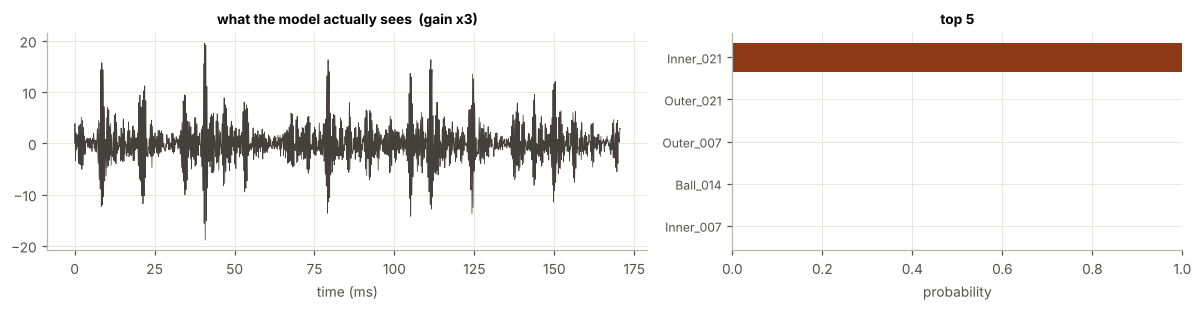

prediction: Inner_021
confidence: 100.0%
truth     : Inner_021   -> CORRECT

full breakdown:
  Inner_021    100.0%  #######################################
  Outer_021      0.0%  
  Outer_007      0.0%  
  Ball_014       0.0%  
  Inner_007      0.0%  
  Ball_021       0.0%  
  Normal         0.0%  
  Inner_014      0.0%  
  Ball_007       0.0%  
  Outer_014      0.0%  


In [30]:
print("=" * 72)
print("the same physical measurement, through a sensor with 3x the gain")
print("=" * 72)
_ = report(prepare_window(raw_snip * 3.0, FS), true_label="Inner_021",
           title="  (gain x3)")

the same measurement recorded at 48 kHz and correctly resampled by prepare_window


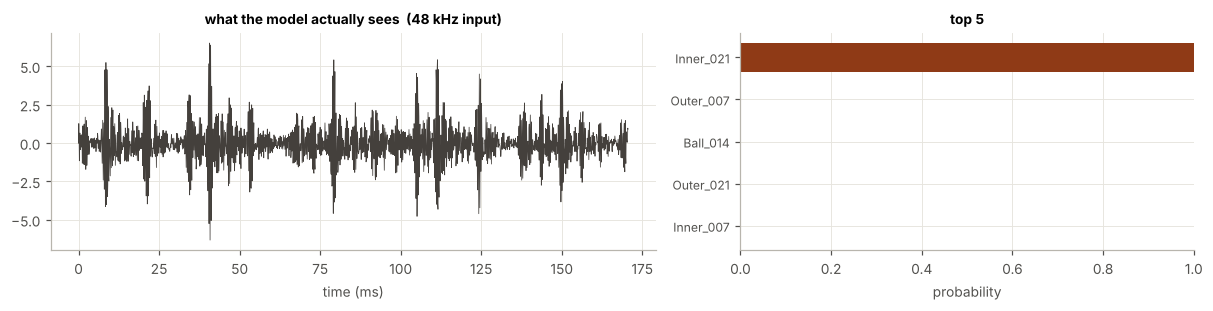

prediction: Inner_021
confidence: 100.0%
truth     : Inner_021   -> CORRECT

full breakdown:
  Inner_021    100.0%  #######################################
  Outer_007      0.0%  
  Ball_014       0.0%  
  Outer_021      0.0%  
  Inner_007      0.0%  
  Ball_007       0.0%  
  Ball_021       0.0%  
  Normal         0.0%  
  Inner_014      0.0%  
  Outer_014      0.0%  


In [31]:
print("=" * 72)
print("the same measurement recorded at 48 kHz and correctly resampled by prepare_window")
print("=" * 72)
up = resample_poly(raw_snip, 4, 1)      # pretend it was acquired at 48 kHz
_ = report(prepare_window(up, 48_000), true_label="Inner_021", title="  (48 kHz input)")

the same 48 kHz data, fed in WITHOUT telling prepare_window the rate


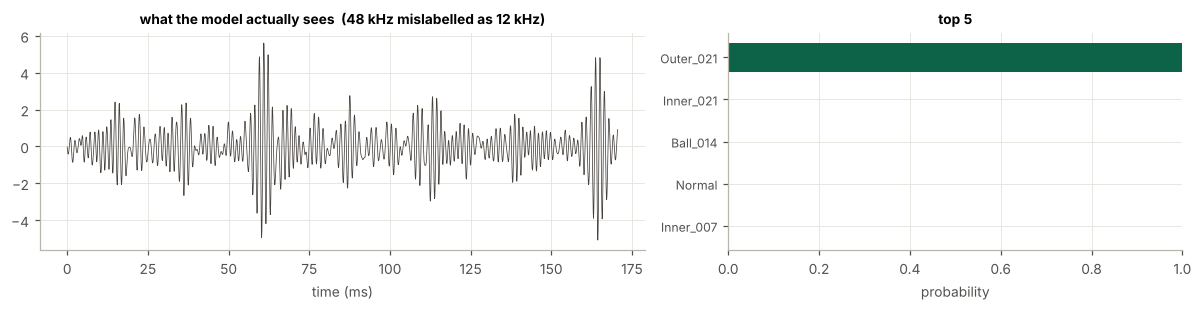

prediction: Outer_021
confidence: 100.0%
truth     : Inner_021   -> WRONG

full breakdown:
  Outer_021    100.0%  ########################################
  Inner_021      0.0%  
  Ball_014       0.0%  
  Normal         0.0%  
  Inner_007      0.0%  
  Outer_014      0.0%  
  Ball_021       0.0%  
  Outer_007      0.0%  
  Inner_014      0.0%  
  Ball_007       0.0%  

Three inputs, one bearing. Changing the sensor gain moves the answer, because amplitude
is a real diagnostic cue and the model was trained on one rig's calibration. Getting the
sampling rate right matters more than anything else, which is the same failure Part I
Task I.2.2 found in the published Normal baseline files: read at the wrong rate, every
frequency in the signal is wrong by the same factor and the diagnosis goes with it.

This is the deployment risk that no held-out split can measure. It is why a two-stage
deployment is the sensible reading of Parts I and II: trust detection and location, treat
severity as advis

In [32]:
print("=" * 72)
print("the same 48 kHz data, fed in WITHOUT telling prepare_window the rate")
print("=" * 72)
_ = report(prepare_window(up, FS), true_label="Inner_021",
           title="  (48 kHz mislabelled as 12 kHz)")
print("""
Three inputs, one bearing. Changing the sensor gain moves the answer, because amplitude
is a real diagnostic cue and the model was trained on one rig's calibration. Getting the
sampling rate right matters more than anything else, which is the same failure Part I
Task I.2.2 found in the published Normal baseline files: read at the wrong rate, every
frequency in the signal is wrong by the same factor and the diagnosis goes with it.

This is the deployment risk that no held-out split can measure. It is why a two-stage
deployment is the sensible reading of Parts I and II: trust detection and location, treat
severity as advisory, and recalibrate against the rig the model will actually run on.""")

## What each CNN-lab method said

One line per technique, on our data.


In [33]:
method_summary = pd.DataFrame([
 ("C2", "dense vs conv", f"one Dense(128) on a raw window costs {dense_cost:,} weights against {(64+1)*16:,} for the conv"),
 ("C3", "what a kernel does", "the smoother destroys window kurtosis, the differencing kernels keep it: impulsiveness is the signal"),
 ("C5", "parameters by hand", f"hand count {sum(by_hand.values()):,} matches Keras exactly; {train_keras:,} of them trainable"),
 ("C6", "pooling", f"with Flatten, dropping pooling costs {f_np/f_p:.1f}x more parameters ({f_p:,} -> {f_np:,}); with global pooling, nothing"),
 ("C8", "label format", "one-hot + categorical and integer + sparse give bit-identical loss"),
 ("C9", "validation_split", "unshuffled it holds back ONE class and reports 0.000; shuffled it reports a leaked number"),
 ("C10", "worst confusions", "the 5-line ranking loop finds Ball_021 -> Ball_014 and Inner_014 immediately"),
 ("C11", "augmentation", f"{gap:+.3f} mean, inside the {widest:.3f} seed spread; {wins}/{pairs} pairwise wins, so promising not proven"),
 ("C12", "save and reload", "reloaded model reproduces predictions exactly"),
 ("C13", "a new measurement", "sampling rate matters most; a 3x sensor gain still classified correctly"),
], columns=["section", "method", "what it said on the bearing data"])
pd.set_option("display.max_colwidth", 110)
print(method_summary.to_string(index=False))
method_summary.to_csv("results/part2_method_summary.csv", index=False)


section             method                                                                             what it said on the bearing data
     C2      dense vs conv                              one Dense(128) on a raw window costs 262,272 weights against 1,040 for the conv
     C3 what a kernel does         the smoother destroys window kurtosis, the differencing kernels keep it: impulsiveness is the signal
     C5 parameters by hand                                              hand count 5,562 matches Keras exactly; 5,466 of them trainable
     C6            pooling with Flatten, dropping pooling costs 3.9x more parameters (130,298 -> 513,274); with global pooling, nothing
     C8       label format                                           one-hot + categorical and integer + sparse give bit-identical loss
     C9   validation_split                    unshuffled it holds back ONE class and reports 0.000; shuffled it reports a leaked number
    C10   worst confusions                      

<a id="individual"></a>
---
# Individual Analysis

> ⚠️ **These three answers must be written by ...** Near-identical answers
> within a group are graded as a single submission and every member receives zero for that
> question. Everything above is shared group work; the wording below must not be. Replace
> the draft prompts with your own writing. Maximum **300 words per question**.

### Question II.1 — Architecture Selection
*Why was RNN/LSTM or CNN suitable for the selected engineering data? Explain the
relationship between the architecture and the input structure.*

Threads to pull on, in your own words:

- The input is a 2048-sample window of a single accelerometer channel. What identifies the
  fault is a short impact transient (tens of samples) that repeats at a rate set by which
  surface is damaged, and it can begin anywhere in the window.
- Convolution is **translation-equivariant** and `GlobalAveragePooling1D` makes the whole
  model **translation-invariant**: the answer does not depend on where the impacts fell.
  Relate that to the fact that the window boundaries are arbitrary.
- The first kernel is 64 samples = 5.3 ms, chosen to span one transient. A 3-sample kernel
  would see only noise. The second, narrow kernel then combines neighbouring detections
  into a spacing, i.e. a rate.
- Why not an LSTM: nothing here depends on order across 2048 steps; the pattern is local
  and periodic. An LSTM would carry state the length of the window, cost far more
  compute, and train sequentially for no gain.
- Worth connecting to Part I: the envelope features extracted exactly this structure by
  hand (band-pass → demodulate → look for a rate). The CNN is being asked to rediscover it.

> *Write your answer here.*

### Question II.2 — Model Performance
*What do the training and validation results indicate? Did the neural network outperform
the baseline meaningfully? Support conclusions with numerical evidence.*

The numbers are printed above; pull the exact values from the comparison table
(`results/part2_comparison.csv`), the seed study (`results/part2_seed_stability.csv`) and
the capacity study (`results/part2_capacity_study.csv`). Points worth addressing:

- Training and validation accuracy both reach **1.000** and the learning curves never
  diverge, yet test macro-F1 is much lower and varies hugely between runs. What does that
  say about what a validation curve can and cannot tell you? The SVMs in Part I did exactly
  the same thing.
- **Be careful how you phrase "outperform".** The single seed-42 run scored 0.7345 against
  the best Part I model's 0.8809, but across five seeds the CNN averages 0.8663, ranges
  0.7345–0.9932, and **2 of 5 seeds beat the best Part I model**. The difference of means
  is 0.0147 while the CNN's own seed spread is 0.2587, i.e. 17.7× larger. State precisely
  what that evidence supports and what it does not.
- The defensible difference is **stability**, not accuracy: the SVM refits identically
  every time, the CNN does not. Argue whether that matters for a system that gets retrained
  as new data arrives.
- Both methods fail on the same records (`Inner_014`, ball severity). Is that a property of
  the models or of the data? Part I Task I.2.6 measured it before either model was fitted.
- 1,622 training windows for 5,466 parameters, against features that already encode the
  bearing physics: how much of the gap is architecture and how much is data volume?
- The capacity study points to a *negative* result. Say so plainly and quantify it.

> *Write your answer here.*

### Question II.3 — Engineering Applicability
*Would you recommend the model for further engineering validation? Identify one important
limitation and propose one additional experiment or improvement.*

Points worth addressing:

- The safety-critical behaviour is good (no fault called healthy, no false alarm), but
  severity grading breaks down. Which of those actually drives a maintenance decision?
- The run-to-run instability is the strongest argument against deployment as it stands.
  A model you cannot reproduce is a model you cannot commission, audit or re-certify.
  Weigh that against the fact that its *average* is competitive.
- If the SVM is cheaper, reproducible and at least as accurate, what is the argument for
  the CNN at all? Consider what changes with far more data, or when fault types are not
  known in advance so features cannot be hand-designed.
- **Pick one limitation** and argue it properly. Candidates: run-to-run variance of 0.24
  macro-F1; one rig with EDM-cut notches rather than service-grown spalls; 1,622 windows
  for 5,466 parameters; the same physical bearing at every load; or that ball severity may
  simply not be present in the signal (0.12–0.14 g RMS across all three sizes).
- **Propose one experiment.** Candidates: a validation set that is actually difficult
  hold out a load at the *edge* of the range rather than the middle, so early stopping has
  something to select on; seed-averaging or an ensemble; overlapping windows as
  training-set augmentation (and why that is legitimate inside training but not across the
  split); leave-one-load-out repeated over all four loads to get an interval rather than a
  point; feeding the CNN the envelope spectrum instead of the raw signal, to separate "the
  architecture is wrong" from "the input representation is wrong".

> *Write your answer here.*

---
### Reproducibility

`keras.utils.set_random_seed` is called inside `build_cnn`, so every model is constructed
and initialised from a stated seed. The split is defined by motor load and involves no
random draw at all. The capacity study reports three seeds per setting precisely because
single-seed deep-learning results are not reproducible claims.

**Note on exact reproducibility.** Seeding fixes initialisation, shuffling and dropout.
CPU thread scheduling in TensorFlow can still reorder floating-point reductions, so a
re-run may differ in the last decimal. Set `tf.config.experimental.enable_op_determinism()`
if bit-exact reruns are needed; it is left off here because it roughly doubles runtime.

In [34]:
print("versions used for the reported results")
import sklearn
for m in (np, pd, sklearn, tf, mpl):
    print(f"  {m.__name__:<12}{m.__version__}")
print(f"\nmax epochs {MAX_EPOCHS}, patience {PATIENCE}, batch {BATCH}, seeds {SEEDS}")
print(f"figures: {sorted(f for f in os.listdir('figures') if f.startswith('ii'))}")
print(f"results: {sorted(f for f in os.listdir('results') if f.startswith('part2'))}")

versions used for the reported results
  numpy       2.5.3
  pandas      3.0.5
  sklearn     1.9.1
  tensorflow  2.21.0
  matplotlib  3.11.2

max epochs 120, patience 15, batch 64, seeds [42, 1, 7]
figures: ['ii3_comparison.png', 'ii3_confusion.png', 'ii3_learning_curves.png', 'ii4_capacity.png', 'ii_lab_c11_augmentation.png', 'ii_lab_c3_kernels.png']
results: ['part2_augmentation.csv', 'part2_capacity_study.csv', 'part2_comparison.csv', 'part2_method_summary.csv', 'part2_seed_stability.csv']
